# Task

The folder "text_files" contains text files written on various topics by two persons. Interests of person 1 and person 2 are very distinct. Note that the file title doesn't necessarily reflect its content.
Use a chosen method of clustering in order to find into which categories/concepts/topics belong these files. Can you say anything relevant about types of these texts or, maybe, about their authors?






In [38]:
import pandas as pd
import os
from sklearn.feature_extraction.text import TfidfVectorizer


In [39]:
# Load Data
folder = 'Data'

data = []

for file in sorted(os.listdir(folder)):
    if file.endswith(".txt"):
        path = os.path.join(folder, file)
        try:
            with open(path, "r", encoding="utf-8") as f:
                content = f.read()
        except UnicodeDecodeError:
            with open(path, "r", encoding="cp1252") as f:
                content = f.read()

        data.append({
            "file_name": file,
            "content": content
        })


df = pd.DataFrame(data)

In [40]:
print('shape of df:', df.shape[0], 'rows')

shape of df: 33 rows


In [41]:
df.head()

,file_name,content
0,Address.txt,"Tonight, as we mark the conclusion of our cele..."
1,Apparition.txt,Sean yawned as he powered down his computer an...
2,Architecture.txt,"In a recent article in Forbes, Jason Bloomberg..."
3,Big.txt,"Big Data metaphors we live by\n\n\n""When Big D..."
4,Breakfast.txt,"Thank you, Mark. So nice. \nThank you very m..."


The next thing that I would do is normalise the text: if we have the exact same word written in a different way, it should count only once (TF-IDF applies lowercase internally). I thought about stemming, but I want to have the words written in a legible way, so I won't use it for this exercise.

In [42]:
tfidf_vectorizer = TfidfVectorizer(stop_words='english') #Load TF-IDF
tfidf_matrix = tfidf_vectorizer.fit_transform(df['content']) #Transform the content into a TF-IDF matrix
tfidf_matrix.shape #Check the shape of the TF-IDF matrix

(33, 6731)

Now that we have the TF-IDF matrix, the next step is clustering. I will use K-Means because we already know that 2 authors wrote the texts, so I can set the k parameter to see if they are separated by author.

In [43]:
#Clustering (KMeans)
from sklearn.cluster import KMeans
k_means = KMeans(n_clusters=2,random_state=67,n_init=10)  
df['cluster'] = k_means.fit_predict(tfidf_matrix)


In [44]:
df[['file_name', 'cluster']].sort_values('cluster')
df['cluster'].value_counts()


cluster
0    21
1    12
Name: count, dtype: int64

In [45]:
terms = tfidf_vectorizer.get_feature_names_out()   # las 6731 palabras, en orden de columna
centroids = k_means.cluster_centers_                # forma (2, 6731): una fila por cluster

for i, centroid in enumerate(centroids):
    top_idx = centroid.argsort()[::-1][:15]         # índices de las 15 palabras con mayor peso
    top_words = terms[top_idx]                      # convertir índices → palabras
    print(f"Cluster {i}: {', '.join(top_words)}")


Cluster 0: data, project, management, decision, example, work, approach, flexibility, enterprise, business, ibis, change, risks, processes, problem
Cluster 1: going, country, people, america, want, thank, great, said, know, american, ve, don, right, prof, think


It's strange: we have business-related words in the first cluster, and in the second one we have something like politics, but it's not super clear. I am going to check it out.

In [46]:
for _, row in df[df['cluster'] == 1].iterrows():
    print(row['file_name'], '→', row['content'][:200], '\n')


Address.txt → Tonight, as we mark the conclusion of our celebration of Black History Month, we are reminded of our Nation's path toward civil rights and the work that still remains. Recent threats targeting Jewish  

Apparition.txt → Sean yawned as he powered down his computer and stretched out in his chair. It was nearly 3 am and he had just finished proofreading his presentation for later that day. He didn't remember ever being  

Breakfast.txt → Thank you, Mark.  So nice.  
Thank you very much.  Thank you.  Thank you very much.  It’s a great honor to be here this morning.  And so many faith leaders — very, very important people to me — from a 

Chiefs.txt → Thank you very much. This is — great to be with people I truly feel comfortable with. Please sit down. They’ll say I didn’t get a standing ovation because they never sat down. And I say, I got one sta 

Dilemma.txt → It felt like a homecoming. That characteristic university smell  (books,  spearmint gum and a hint of cologne) per

Okay, we have a mix of politics and storytelling. This is due to the k=2 that we assigned before; of course, one author can write about different topics using different vocabulary, so it's impossible to have two completely separated clusters by author. I will calculate the silhouette score to see what the appropriate number of clusters is for this case.

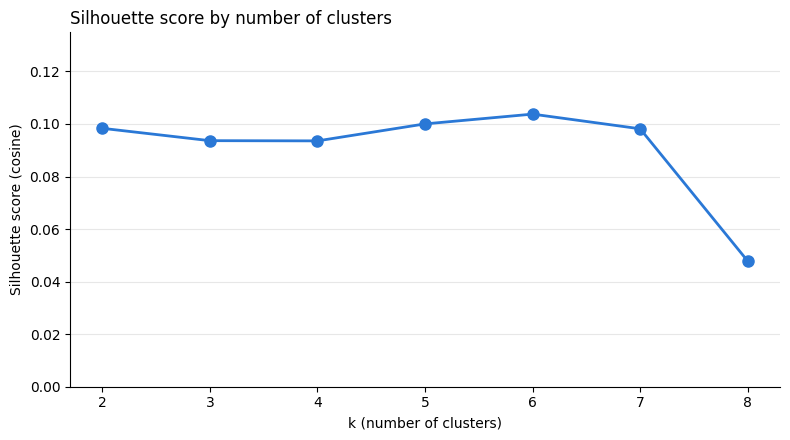

In [47]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

ks = range(2, 9)
scores = []
for k in ks:
    labels = KMeans(n_clusters=k, random_state=67, n_init=10).fit_predict(tfidf_matrix)
    scores.append(silhouette_score(tfidf_matrix, labels, metric='cosine'))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(list(ks), scores, color='#2a78d6', linewidth=2, marker='o', markersize=8)
ax.set_ylim(0, max(scores) * 1.3)   # eje desde 0 para no exagerar diferencias pequeñas
ax.set_title('Silhouette score by number of clusters', loc='left')
ax.set_xlabel('k (number of clusters)'); ax.set_ylabel('Silhouette score (cosine)')
ax.set_xticks(list(ks))
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()


Okay, we don't have a major shift in the silhouette score for k values from 2 to 7, so we can pick any value in that range. Of course, the problem that we are trying to solve dictates the number of clusters; in this case we wanted to know if the texts would be clustered by author if we assigned k=2, so I would stick with that option.

Implementation for k=3,4

In [48]:
# Test: K-Means with k=3 and k=4
terms = tfidf_vectorizer.get_feature_names_out()

for k in [3, 4]:
    km = KMeans(n_clusters=k, random_state=67, n_init=10)
    labels = km.fit_predict(tfidf_matrix)
    print(f"========== k = {k} ==========")
    for c in range(k):
        docs = df.loc[labels == c, 'file_name'].str.replace('.txt', '').tolist()
        top_words = terms[km.cluster_centers_[c].argsort()[::-1][:10]]
        print(f"\nCluster {c} ({len(docs)} docs)")
        print("  Docs: ", ', '.join(docs))
        print("  Words:", ', '.join(top_words))
    print()

========== k = 3 ==========

Cluster 0 (10 docs)
  Docs:  Change, Dilemma, EnterpriseIT, Entrepreneurship, Managing, Objectivity, Politicians, Systems, Uncertainty, Within
  Words: decision, prof, risks, management, project, approach, consultants, uncertainty, example, internally

Cluster 1 (10 docs)
  Docs:  Address, Breakfast, Chiefs, Failure, Florida, Immigration, Nomination, Off, People, Speech
  Words: going, country, people, america, want, great, thank, american, know, don

Cluster 2 (13 docs)
  Docs:  Apparition, Architecture, Big, Design, Faces, Flexibility, ForBI, Knowledge, Parmenides, Projects, Reality, Relationships, Surprise
  Words: data, flexibility, ibis, sean, enterprise, surprises, metaphors, work, business, routines

========== k = 4 ==========

Cluster 0 (9 docs)
  Docs:  Architecture, Change, EnterpriseIT, Entrepreneurship, ForBI, Objectivity, Relationships, Systems, Uncertainty
  Words: data, decision, approach, business, uncertainty, example, enterprise, model, e

After running K-Means with k=3 and k=4, I've come to realize that each cluster has similar words, so we can clearly identify the topics just by taking a quick look. When using k=4, we can notice that cluster 1 kept the storytelling documents, which helped a lot to get more homogeneous clusters.

# Conclusion

Okay, so after testing k=2, 3 and 4, this is what I found.

**Types of texts.** There are three types of texts:
- **Political speeches** (Address, Breakfast, Chiefs, Failure, Florida, Immigration, Nomination, Off, People, Speech): spoken language, very repetitive, with words like *going, country, people, america, great, thank* and contractions like *don* and *ve*.
- **Essays about business and management**: more formal and technical vocabulary like *data, decision, project, management, uncertainty, enterprise*. With k=3 and k=4 they split into subtopics, like decision making and uncertainty on one side and data, flexibility and knowledge management (IBIS) on the other.
- **Short stories** (Apparition and Dilemma): narrative texts with characters (*sean, prof, said*), which is why with k=4 they got their own cluster.

**The authors.**
- **Person 2** is a politician. The speeches mention Obamacare, CPAC, Melania and "make America great", so they look like Donald Trump's speeches from around 2016-2017.
- **Person 1** writes about management, projects, data and decision making. The short stories also happen in that world (a consultant, a professor, a work presentation), so I think they are from the same author, who writes both essays and fiction.

**About separating by author.** Before, I said it was impossible to get two clusters separated by author, but looking at k=3, the speeches end up completely alone in one cluster and the stories go with the business texts. So the split by author does show up in the data. With k=2 the stories got mixed with the speeches, probably because both use more informal, narrative language (*said, don, ve*). This shows that K-Means groups texts by vocabulary and topic, not directly by author; it works here because the two authors have very different interests.